<div style="display: flex; background-color: RGB(227, 128, 23);" >
<h1 style="margin: auto; padding: 30px; ">ANALYSE DU VENTES DE LA LIBRAIRIE LAPAGE - partie 2 </h1>
</div>

## L'objectif de ce Notebook

Cette section 2 présente une analyse de compartement de clients au ligne.

Cette analyse repose sur des analyses de corrélation.


<div style="background-color: RGB(227, 128, 23);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - Importation des librairies et chargement des jeux des données</h2>
</div>

<div style="border: 2px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">1.1 - Importation des librairies</h3>
</div>

In [70]:
# importation des  librairies
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
from scipy.stats import norm
from scipy.stats import shapiro
from scipy.stats import chi2_contingency
from scipy.stats import pearsonr
from scipy.stats import spearmanr
from scipy.stats import f_oneway
import statsmodels.api as sm
from statsmodels.stats.multicomp import pairwise_tukeyhsd


<div style="border: 2px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">1.1 - Chargement des jeux de donnéess</h3>
</div>

In [14]:
os.listdir()

['.anaconda',
 '.conda',
 '.condarc',
 '.continuum',
 '.ipynb_checkpoints',
 '.ipython',
 '.jupyter',
 '.matplotlib',
 '.ms-ad',
 '.vscode',
 'anaconda3',
 'anaconda_projects',
 'AppData',
 'Application Data',
 'Contacts',
 'Cookies',
 'df_all_sans_BtoB.csv',
 'Documents',
 'Downloads',
 'Favorites',
 'Haraldsson_Matilda_1b_notebook_022026.ipynb',
 'Haraldsson_Matilda_3_notebook_022026.ipynb',
 'Links',
 'Local Settings',
 'Music',
 'My Documents',
 'NetHood',
 'NTUSER.DAT',
 'ntuser.dat.LOG1',
 'ntuser.dat.LOG2',
 'NTUSER.DAT{2fb145d9-ff20-11ef-9972-e2aa0de23cc1}.TM.blf',
 'NTUSER.DAT{2fb145d9-ff20-11ef-9972-e2aa0de23cc1}.TMContainer00000000000000000001.regtrans-ms',
 'NTUSER.DAT{2fb145d9-ff20-11ef-9972-e2aa0de23cc1}.TMContainer00000000000000000002.regtrans-ms',
 'ntuser.ini',
 'OneDrive',
 'PrintHood',
 'Recent',
 'Saved Games',
 'Searches',
 'SendTo',
 'Start Menu',
 'Templates',
 'Tra s.ipynb',
 'Transactions_compare.ipynb',
 'Untitled.ipynb',
 'Untitled1.ipynb',
 'Untitled2.ipynb'

In [23]:
# Importation du fichier df_all_sans_BtoB
df_all_sans_BtoB = pd.read_csv("df_all_sans_BtoB.csv")
df_all_sans_BtoB.head()

,Unnamed: 0,id_prod,date,session_id,client_id,sex,birth,age,price,categ,date_y_m_d,date_y_m,age_decade
0,480353,0_1259,2021-03-01 00:01:07.843138,s_1,c_329,f,1967,59,11.99,0,2021-03-01,2021-03,50
1,428221,0_1390,2021-03-01 00:02:26.047414,s_2,c_664,m,1960,66,19.37,0,2021-03-01,2021-03,60
2,462423,0_1352,2021-03-01 00:02:38.311413,s_3,c_580,m,1988,38,4.50,0,2021-03-01,2021-03,30
3,488002,0_1458,2021-03-01 00:04:54.559692,s_4,c_7912,f,1989,37,6.55,0,2021-03-01,2021-03,30
4,438813,0_1358,2021-03-01 00:05:18.801198,s_5,c_2033,f,1956,70,16.49,0,2021-03-01,2021-03,70


<div style="background-color: RGB(227, 128, 23);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Analyse de compartement de clients au ligne</h2>
</div>

## Note sur les données:
Comme il s'agit d'une analyse du comportement des clients, nous n'incluons pas les clients B to B, car elles ne reflètent pas le comportement des clients individuels.


In [24]:
# group les données by clients - calculer les valeur de differents variable utilisée dans les correlations

# le genre d’un client et les catégories des livres - Chi2
# df_all_sans_BtoB => voir ci-dessous

# l'âge des clients et le montant total des achats - Correlation
# l'âge des clients et la fréquence d’achat
df_group_clients = df_all_sans_BtoB[["id_prod","session_id","client_id","price","age","sex"]].groupby("client_id").agg({"age":"min","price":"sum","session_id":"nunique","sex":"min"})
df_group_clients = df_group_clients.reset_index() # reset l'index
df_group_clients = df_group_clients.rename(columns={"price": "price_tot","session_id":"freq_achats"})
df_group_clients.sort_values("price_tot", ascending=False).head(3)

# l'âge des clients et la taille du panier moyen
df_group_clients_session = df_all_sans_BtoB[["id_prod","session_id","client_id","price","age"]].groupby(["client_id","session_id"]).agg({"age":"min","id_prod":"nunique"})
df_group_clients_session = df_group_clients_session.reset_index() # reset l'index 
df_group_clients_panier = df_group_clients_session.groupby(["client_id"]).agg({"age":"min","id_prod":"mean"})
df_group_clients_panier = df_group_clients_panier.reset_index() # reset l'index 
df_group_clients_panier = df_group_clients_panier.rename(columns={"id_prod": "panier_moyen"})

# l'âge des clients et la catégorie des livres achetés - Anova
# df_all_sans_BtoB => voir ci-dessous


<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">Etape 2.1 - Corrélation: genre de client versus catégorie des livres achetés</h3>
</div>

In [28]:
# correlation entres deux variable categorique (genre et catégorie de livres) => analyse de Chi-2
print("La corrélation entre deux variables catégorielles nécessite un test du chi-2")
print()
#print()
print("H0:   Il n'y a pas de relation entres les deux variables genre et la catégorie de livres")
print()
print("H1:   Il existe une relation entre les deux variables genre et catégorie de livres, \n      c'est-à-dire que la catégorie de livres qu'une personne achètera dépend de son genre")
print()
print()


La corrélation entre deux variables catégorielles nécessite un test du chi-2

H0:   Il n'y a pas de relation entres les deux variables genre et la catégorie de livres

H1:   Il existe une relation entre les deux variables genre et catégorie de livres, 
      c'est-à-dire que la catégorie de livres qu'une personne achètera dépend de son genre




In [29]:
# les données utilise - dataset complet
df_all_sans_BtoB.head(3)


,Unnamed: 0,id_prod,date,session_id,client_id,sex,birth,age,price,categ,date_y_m_d,date_y_m,age_decade
0,480353,0_1259,2021-03-01 00:01:07.843138,s_1,c_329,f,1967,59,11.99,0,2021-03-01,2021-03,50
1,428221,0_1390,2021-03-01 00:02:26.047414,s_2,c_664,m,1960,66,19.37,0,2021-03-01,2021-03,60
2,462423,0_1352,2021-03-01 00:02:38.311413,s_3,c_580,m,1988,38,4.50,0,2021-03-01,2021-03,30


In [30]:
# test Chi 2
# Créer le tableau de contingence
contingency_table = pd.crosstab(df_all_sans_BtoB["sex"], df_all_sans_BtoB["categ"])

# Calculer le test du Chi-2
chi2_stat, p_value, dof, expected = chi2_contingency(contingency_table)

print(f"Statistique Chi-2: {chi2_stat}")
print(f"Valeur p: {p_value}")
print(f"Degrés de liberté: {dof}")
print("Fréquences attendues:")
print()

# l'interpretation
alpha = 0.05
print("p value is " + str(p_value))
if float(p_value) <= alpha:
    print('Dependent (reject H0)')
else:
    print('Independent (H0 holds true)')


Statistique Chi-2: 20.213460693513895
Valeur p: 4.080400389217356e-05
Degrés de liberté: 2
Fréquences attendues:

p value is 4.080400389217356e-05
Dependent (reject H0)


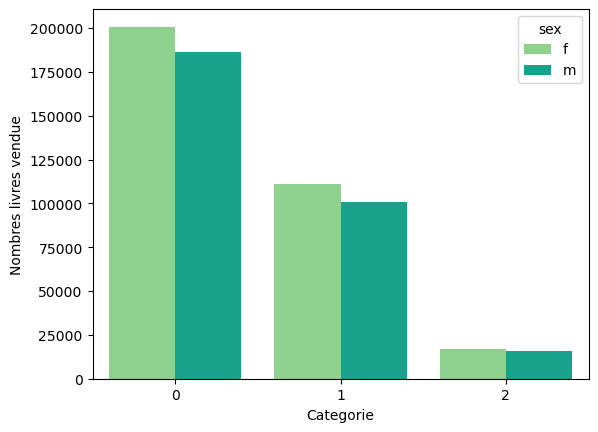

In [32]:
# Visualizer avec une barplot
#sns.barplot(data = contingency_table, x = "categ")
df_contingency = df_all_sans_BtoB.groupby(by=["categ","sex"]).agg({"client_id":"count"})
df_contingency = df_contingency.reset_index()

sns.barplot(data=df_contingency, x = "categ", y = "client_id", hue = "sex", palette = ["#84de81","#00b99a"]) # ["#D9AD30","#d5a419", "#0077AB","#006390","#33a6b7","#008fa4"])
plt.ylabel("Nombres livres vendue")
plt.xlabel("Categorie")
plt.savefig("fig_contingency_plot.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.
plt.show()


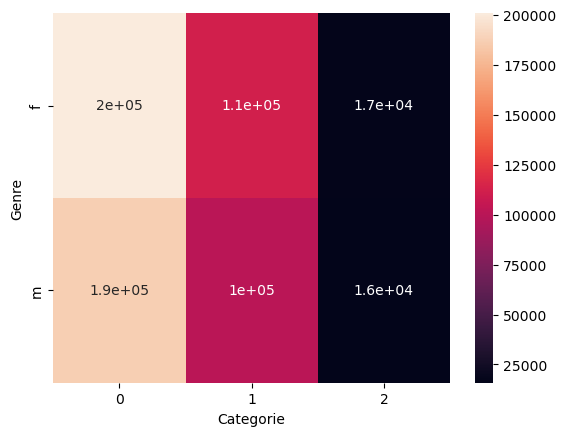

In [31]:
# Visualizer les contingency table
sns.heatmap(contingency_table, annot=True)
plt.xlabel("Categorie")
plt.ylabel("Genre")
plt.savefig("fig_contingency_table.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.


<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">Etape 2.2 - Corrélation: age versus montant total des achetés </h3>
</div>

In [33]:
# correlation entres deux variables quantitative (l'age et montant total d'achetés) => correlation
print("La corrélation entre deux variables quantitative (l'age et montant total d'achetés) => test de correlation")
print()
#print()
print("H0:   Il n'y a pas de relation entres les deux variables l'age et montant total d'achatés")
print()
print("H1:   Il existe une relation entre les deux variables genre et catégorie de livres, \n      c'est-à-dire que, selon l'âge du client, il achètera un livre plus ou moins cher")


La corrélation entre deux variables quantitative (l'age et montant total d'achetés) => test de correlation

H0:   Il n'y a pas de relation entres les deux variables l'age et montant total d'achatés

H1:   Il existe une relation entre les deux variables genre et catégorie de livres, 
      c'est-à-dire que, selon l'âge du client, il achètera un livre plus ou moins cher


In [35]:
# le donnée (l'age et price_tot)
df_group_clients.head(3)

,client_id,age,price_tot,freq_achats,sex
0,c_1,71,558.18,33,m
1,c_10,70,1353.60,34,m
2,c_100,34,254.85,5,m


Moyenne du l'age : 47.739646347138205
Écart type du l'age : 16.91054150589733
Moyenne du montant : 1276.4888483015357
Écart type du montant : 954.1822746196469

Les deux ensembles de données présentent une asymétrie négative et ne semblent pas respecter les lois de la normalité



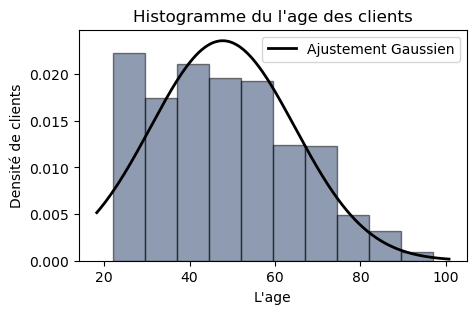

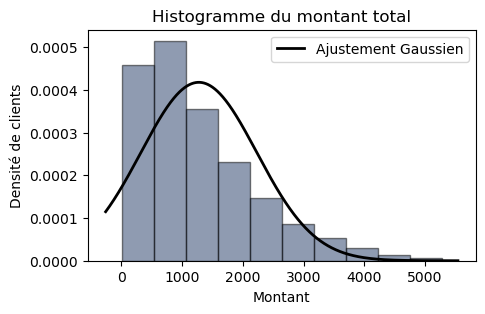

In [36]:
# Visualiser le distribution des variables - sont-elles normalement distribuées
# Extraire la colonne 'l'age'
age = df_group_clients["age"]

# Extraire la colonne 'montant total'
montant = df_group_clients["price_tot"]

# Calculer la moyenne et l'écart type
mean_age = age.mean()
std_age = age.std()

mean_montant = montant.mean()
std_montant = montant.std()

# Afficher les valeurs calculées
print(f"Moyenne du l'age : {mean_age}")
print(f"Écart type du l'age : {std_age}")

print(f"Moyenne du montant : {mean_montant}")
print(f"Écart type du montant : {std_montant}")
print()

print("Les deux ensembles de données présentent une asymétrie négative et ne semblent pas respecter les lois de la normalité")
print()


# Tracer l'histogramme avec une courbe gaussienne

### L'age ###
# Histogramme - L'age
plt.figure(figsize=(5, 3))
plt.hist(age, bins=10, density=True, color='#203864', edgecolor='black', alpha=0.5)

# Ajustement gaussien
mu, std = norm.fit(age)
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, age.count())
p = norm.pdf(x, mu, std)

# Tracer la courbe gaussienne
plt.plot(x, p, 'k', linewidth=2, label='Ajustement Gaussien')

# Ajouter les titres et légendes en français
plt.title("Histogramme du l'age des clients")
plt.xlabel("L'age")
plt.ylabel("Densité de clients")
plt.legend()
plt.savefig("Hist_norm_age.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.
plt.show()

### Montant ###
# Histogramme - Montant
plt.figure(figsize=(5, 3))
plt.hist(montant, bins=10, density=True, color='#203864', edgecolor='black', alpha=0.5)

# Ajustement gaussien
mu, std = norm.fit(montant)
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, montant.count())
p = norm.pdf(x, mu, std)

# Tracer la courbe gaussienne
plt.plot(x, p, 'k', linewidth=2, label='Ajustement Gaussien')

# Ajouter les titres et légendes en français
plt.title("Histogramme du montant total")
plt.xlabel("Montant")
plt.ylabel("Densité de clients")
plt.legend()

# Afficher le graphique
plt.savefig("Hist_norm_Montant.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.
plt.show()


In [37]:
# Test Shapiro pour tester la normalite

### L'age ###
# Effectuer le test de Shapiro-Wilk
print("Shapiro test pour le variable l'age")
stat, p_value = shapiro(age)

# Afficher les résultats
print(f"Statistique du test de Shapiro-Wilk : {stat:,.2f}")
print(f"Valeur p : {p_value:,.4f}")

# Interprétation des résultats
alpha = 0.05
if p_value > alpha:
    print("Les données suivent une distribution normale (on ne rejette pas H0)")
else:
    print("Les données ne suivent pas une distribution normale (on rejette H0)")
print()

### Montant ###
# Effectuer le test de Shapiro-Wilk
print("Shapiro test pour le variable montant total")
stat, p_value = shapiro(montant)

# Afficher les résultats
print(f"Statistique du test de Shapiro-Wilk : {stat:,.2f}")
print(f"Valeur p : {p_value:,.4f}")

# Interprétation des résultats
alpha = 0.05
if p_value > alpha:
    print("Les données suivent une distribution normale (on ne rejette pas H0)")
else:
    print("Les données ne suivent pas une distribution normale (on rejette H0)")
print()

print("Les tests de Shapiro confirme les histogrammes")


Shapiro test pour le variable l'age
Statistique du test de Shapiro-Wilk : 0.97
Valeur p : 0.0000
Les données ne suivent pas une distribution normale (on rejette H0)

Shapiro test pour le variable montant total
Statistique du test de Shapiro-Wilk : 0.90
Valeur p : 0.0000
Les données ne suivent pas une distribution normale (on rejette H0)

Les tests de Shapiro confirme les histogrammes


C:\Users\matil\anaconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:531: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 8596.
  res = hypotest_fun_out(*samples, **kwds)


In [38]:
# Test Shapiro pour tester la normalite sur données transforme
# Comme le test de Shapiro ci-dessus a montré que les données ne suivaient pas une distribution normale, 
# nous allons vérifier si les données transformées par la racine carrée suivent une distribution normale.


### L'age ###
# Effectuer le test de Shapiro-Wilk
print("Shapiro test pour le variable l'age racine carre transformé")
stat, p_value = shapiro(np.sqrt(age))

# Afficher les résultats
print(f"Statistique du test de Shapiro-Wilk : {stat:,.2f}")
print(f"Valeur p : {p_value:,.4f}")

# Interprétation des résultats
alpha = 0.05
if p_value > alpha:
    print("Les données suivent une distribution normale (on ne rejette pas H0)")
else:
    print("Les données ne suivent pas une distribution normale (on rejette H0)")
print()

### Montant ###
# Effectuer le test de Shapiro-Wilk
print("Shapiro test pour le variable montant total racine carre transformé")
stat, p_value = shapiro(np.sqrt(montant))

# Afficher les résultats
print(f"Statistique du test de Shapiro-Wilk : {stat:,.2f}")
print(f"Valeur p : {p_value:,.4f}")

# Interprétation des résultats
alpha = 0.05
if p_value > alpha:
    print("Les données suivent une distribution normale (on ne rejette pas H0)")
else:
    print("Les données ne suivent pas une distribution normale (on rejette H0)")
print()

print("Les tests de Shapiro confirme les histogrammes")


Shapiro test pour le variable l'age racine carre transformé
Statistique du test de Shapiro-Wilk : 0.98
Valeur p : 0.0000
Les données ne suivent pas une distribution normale (on rejette H0)

Shapiro test pour le variable montant total racine carre transformé
Statistique du test de Shapiro-Wilk : 0.99
Valeur p : 0.0000
Les données ne suivent pas une distribution normale (on rejette H0)

Les tests de Shapiro confirme les histogrammes


In [40]:
# Comme ni les données brutes ni les données transformées ne suivent une distribution normale, 
# nous devrons effectuer un test non paramétrique: Spearmans rank correlation 
df_group_clients.head(2)

,client_id,age,price_tot,freq_achats,sex
0,c_1,71,558.18,33,m
1,c_10,70,1353.60,34,m



Coefficient de corrélation de Spearman: -0.185
Valeur p: 3.7882642621417936e-67

Conclusions: Les deux tests indiquent une faible corrélation négative, hautement significative. 
Il convient d'être prudent compte tenu de la taille très importante de l'échantillon, qui peut rendre significatives de faibles corrélations.



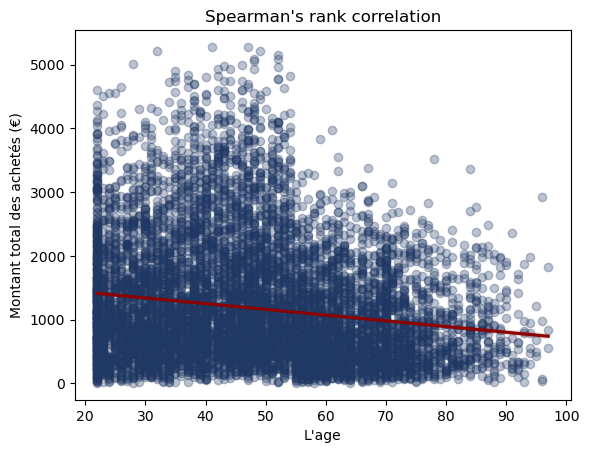

In [45]:
# test Spearmans correlation, non parametric
# Extraire les colonnes pertinentes
age = (df_group_clients["age"])
montant = (df_group_clients["price_tot"])

# Visualisation de la tendance
sns.regplot(x=age, y=montant, robust=True, scatter_kws = {"color": "#203864", "alpha": 0.3}, line_kws=dict(color="darkred"))
#sns.regplot(x=age, y=montant, robust=True, line_kws={"linestyle": "--", "color": "#203864", "alpha": 0.3}, line_kws=dict(color="darkred"))
plt.title("Spearman's rank correlation")
plt.xlabel("L'age")
plt.ylabel("Montant total des achetés (€)")
plt.savefig("fig_Spearmans_corr_age_montant_total.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.

print()

# Calculer le coefficient de corrélation de Spearman et la valeur p
spearman_corr, spearman_p_value = spearmanr(age, montant)

print(f"Coefficient de corrélation de Spearman: {spearman_corr:,.3f}")
print(f"Valeur p: {spearman_p_value}")
print()

print("Conclusions: Les deux tests indiquent une faible corrélation négative, hautement significative. \nIl convient d'être prudent compte tenu de la taille très importante de l'échantillon, qui peut rendre significatives de faibles corrélations.")
print()


Coefficient de corrélation de Pearson avec données sqrt-transforme: -0.182
Valeur p: 9.129062298669808e-65



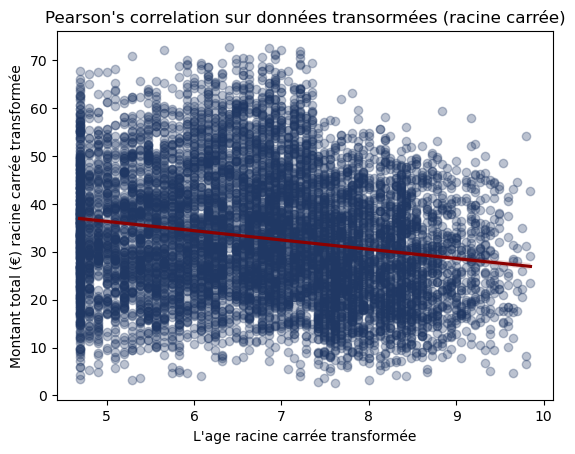

In [46]:
# À titre de comparaison, nous effectuons un test de corrélation de Pearson sur les données transformées par la racine carrée.
# test Pearson correlation avec transformations
# Les données
df_group_clients

# Extraire les colonnes pertinentes et transformes le
age = np.sqrt(df_group_clients["age"])
montant = np.sqrt(df_group_clients["price_tot"])

# Visualisation de la tendance
sns.regplot(x=age, y=montant, robust=True, scatter_kws = {"color": "#203864", "alpha": 0.3}, line_kws=dict(color="darkred"))
plt.title("Pearson's correlation sur données transormées (racine carrée)")
plt.xlabel("L'age racine carrée transformée")
plt.ylabel("Montant total (€) racine carrée transformée")
plt.savefig("fig_Pearsons_corr_age_montant_total.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.

print()

# Calculer le coefficient de corrélation de Pearson et la valeur p
correlation, p_value = pearsonr(age, montant)

print(f"Coefficient de corrélation de Pearson avec données sqrt-transforme: {correlation:,.3f}")
print(f"Valeur p: {p_value}")
print()


<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">Etape 2.3 - Corrélation: age versus fréquence d achat</h3>
</div>

In [47]:
# correlation entres deux variables quantitative (l'age et fréquence d'achetés (par client)) => correlation
print("La corrélation entre deux variables quantitative (l'age et fréquence d'achetés (par client)) => test de correlation")
print()
#print()
print("H0:   Il n'y a pas de relation entres les deux variables l'age et montant total d'achatés")
print()
print("H1:   Il existe une relation entre les deux variables genre et catégorie de livres, \n      c'est-à-dire que lorsque l'âge d'un client change, le fréquence d'achetés change également")


La corrélation entre deux variables quantitative (l'age et fréquence d'achetés (par client)) => test de correlation

H0:   Il n'y a pas de relation entres les deux variables l'age et montant total d'achatés

H1:   Il existe une relation entre les deux variables genre et catégorie de livres, 
      c'est-à-dire que lorsque l'âge d'un client change, le fréquence d'achetés change également


In [48]:
# le donnée (l'age et fréquence d'achat)
df_group_clients.head(3)

,client_id,age,price_tot,freq_achats,sex
0,c_1,71,558.18,33,m
1,c_10,70,1353.60,34,m
2,c_100,34,254.85,5,m


Moyenne du l'age : 6.80
Écart type du l'age : 1.23
Moyenne du freqance d'achats : 5.61
Écart type du freqance d'achats : 2.38

Les deux ensembles de données présentent une asymétrie négative et ne semblent pas respecter les lois de la normalité



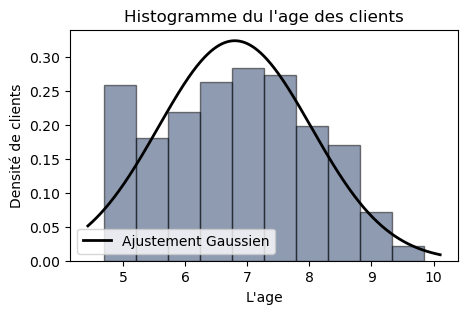

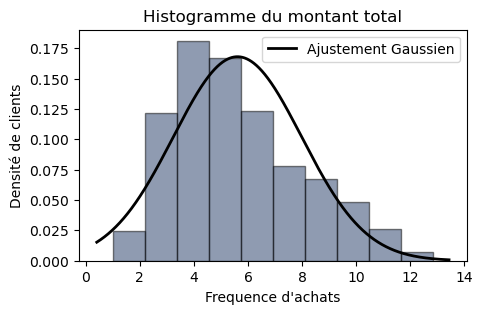

In [49]:
# Visualiser le distribution des variables
# Extraire la colonne 'l'age'
age = np.sqrt(df_group_clients["age"])

# Extraire la colonne 'montant total'
freq = np.sqrt(df_group_clients["freq_achats"])

# Calculer la moyenne et l'écart type
mean_age = age.mean()
std_age = age.std()

mean_freq = freq.mean()
std_freq = freq.std()

# Afficher les valeurs calculées
print(f"Moyenne du l'age : {mean_age:,.2f}")
print(f"Écart type du l'age : {std_age:,.2f}")

print(f"Moyenne du freqance d'achats : {mean_freq:,.2f}")
print(f"Écart type du freqance d'achats : {std_freq:,.2f}")
print()

print("Les deux ensembles de données présentent une asymétrie négative et ne semblent pas respecter les lois de la normalité")
print()


# Tracer l'histogramme avec une courbe gaussienne

### L'age ###
# Histogramme - L'age
plt.figure(figsize=(5, 3))
plt.hist(age, bins=10, density=True, color='#203864', edgecolor='black', alpha=0.5)

# Ajustement gaussien
mu, std = norm.fit(age)
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, age.count())
p = norm.pdf(x, mu, std)

# Tracer la courbe gaussienne
plt.plot(x, p, 'k', linewidth=2, label='Ajustement Gaussien')

# Ajouter les titres et légendes en français
plt.title("Histogramme du l'age des clients")
plt.xlabel("L'age")
plt.ylabel("Densité de clients")
plt.legend()
plt.show()

### Montant ###
# Histogramme - Montant
plt.figure(figsize=(5, 3))
plt.hist(freq, bins=10, density=True, color='#203864', edgecolor='black', alpha=0.5)

# Ajustement gaussien
mu, std = norm.fit(freq)
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, montant.count())
p = norm.pdf(x, mu, std)

# Tracer la courbe gaussienne
plt.plot(x, p, 'k', linewidth=2, label='Ajustement Gaussien')

# Ajouter les titres et légendes en français
plt.title("Histogramme du montant total")
plt.xlabel("Frequence d'achats")
plt.ylabel("Densité de clients")
plt.legend()

# Afficher le graphique
plt.savefig("Hist_norm_freq_achats.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.
plt.show()


In [50]:
# Test Shapiro pour tester la normalite

### L'age ###
# Effectuer le test de Shapiro-Wilk
print("Shapiro test pour le variable l'age")
stat, p_value = shapiro(age)

# Afficher les résultats
print(f"Statistique du test de Shapiro-Wilk : {stat:,.2f}")
print(f"Valeur p : {p_value:,.4f}")

# Interprétation des résultats
alpha = 0.05
if p_value > alpha:
    print("Les données suivent une distribution normale (on ne rejette pas H0)")
else:
    print("Les données ne suivent pas une distribution normale (on rejette H0)")
print()

### Frequence d'achats ###
# Effectuer le test de Shapiro-Wilk
print("Shapiro test pour le variable frequence d'achats")
stat, p_value = shapiro(freq)

# Afficher les résultats
print(f"Statistique du test de Shapiro-Wilk : {stat:,.2f}")
print(f"Valeur p : {p_value:,.4f}")

# Interprétation des résultats
alpha = 0.05
if p_value > alpha:
    print("Les données suivent une distribution normale (on ne rejette pas H0)")
else:
    print("Les données ne suivent pas une distribution normale (on rejette H0)")
print()

print("Les tests de Shapiro confirme les histogrammes")


Shapiro test pour le variable l'age
Statistique du test de Shapiro-Wilk : 0.98
Valeur p : 0.0000
Les données ne suivent pas une distribution normale (on rejette H0)

Shapiro test pour le variable frequence d'achats
Statistique du test de Shapiro-Wilk : 0.96
Valeur p : 0.0000
Les données ne suivent pas une distribution normale (on rejette H0)

Les tests de Shapiro confirme les histogrammes


C:\Users\matil\anaconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:531: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 8596.
  res = hypotest_fun_out(*samples, **kwds)


In [53]:
# Test Shapiro pour tester la normalite sur données transforme

### L'age ###
# Effectuer le test de Shapiro-Wilk
print("Shapiro test pour le variable l'age racine carre transformé")
stat, p_value = shapiro(np.sqrt(age))

# Afficher les résultats
print(f"Statistique du test de Shapiro-Wilk : {stat:,.2f}")
print(f"Valeur p : {p_value}")

# Interprétation des résultats
alpha = 0.05
if p_value > alpha:
    print("Les données suivent une distribution normale (on ne rejette pas H0)")
else:
    print("Les données ne suivent pas une distribution normale (on rejette H0)")
print()

### Frequence d'achats ###
# Effectuer le test de Shapiro-Wilk
print("Shapiro test pour le variable frequence d'achats racine carre transformé")
stat, p_value = shapiro(np.sqrt(freq))

# Afficher les résultats
print(f"Statistique du test de Shapiro-Wilk : {stat:,.2f}")
print(f"Valeur p : {p_value}")

# Interprétation des résultats
alpha = 0.05
if p_value > alpha:
    print("Les données suivent une distribution normale (on ne rejette pas H0)")
else:
    print("Les données ne suivent pas une distribution normale (on rejette H0)")
print()

print("Les tests de Shapiro confirme les histogrammes")


Shapiro test pour le variable l'age racine carre transformé
Statistique du test de Shapiro-Wilk : 0.98
Valeur p : 9.99132897306574e-35
Les données ne suivent pas une distribution normale (on rejette H0)

Shapiro test pour le variable frequence d'achats racine carre transformé
Statistique du test de Shapiro-Wilk : 0.96
Valeur p : 3.0222123581783542e-43
Les données ne suivent pas une distribution normale (on rejette H0)

Les tests de Shapiro confirme les histogrammes


C:\Users\matil\anaconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:531: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 8596.
  res = hypotest_fun_out(*samples, **kwds)


In [54]:
# Comme les variables ne suivent pas une distribution normale, on dois faire une:
# test Spearmans correlation, non parametric



Coefficient de corrélation de Spearman: 0.212
Valeur p: 3.5049079111602286e-88

Conclusions: Le test indiquent une faible corrélation positive, hautement significative. 
Il convient d'être prudent compte tenu de la taille très importante de l'échantillon, qui peut rendre significatives de faibles corrélations.



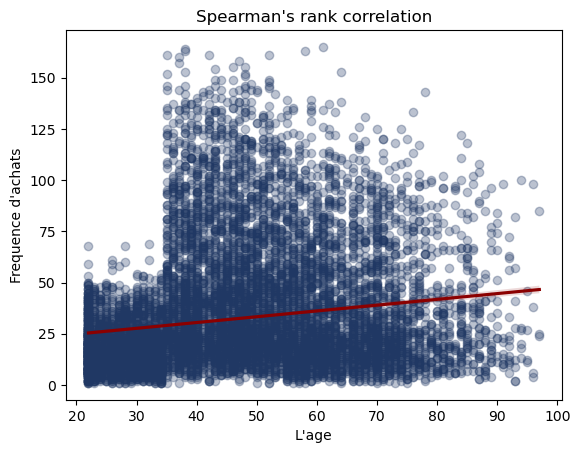

In [52]:
# test Spearmans correlation, non parametric
# Extraire les colonnes pertinentes
age = (df_group_clients["age"])
freq = (df_group_clients["freq_achats"])

# Visualisation de la tendance
sns.regplot(x=age, y=freq, robust=True, scatter_kws = {"color": "#203864", "alpha": 0.3}, line_kws=dict(color="darkred"))
plt.title("Spearman's rank correlation")
plt.xlabel("L'age")
plt.ylabel("Frequence d'achats")
plt.savefig("fig_Spearmans_corr_age_freq_achats.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.

print()

# Calculer le coefficient de corrélation de Spearman et la valeur p
spearman_corr, spearman_p_value = spearmanr(age, freq)

print(f"Coefficient de corrélation de Spearman: {spearman_corr:,.3f}")
print(f"Valeur p: {spearman_p_value}")
print()

print("Conclusions: Le test indiquent une faible corrélation positive, hautement significative. \nIl convient d'être prudent compte tenu de la taille très importante de l'échantillon, qui peut rendre significatives de faibles corrélations.")
print()

<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">Etape 2.4 - Corrélation: age versus taille du panier moyen</h3>
</div>

In [55]:
# correlation entres deux variables quantitative (l'age et taille du panier) => correlation
print("La corrélation entre deux variables quantitative (l'age et taille du panier) => test de correlation")
print()
#print()
print("H0:   Il n'y a pas de relation entres les deux variables l'age et taille du panier")
print()
print("H1:   Il existe une relation entre les deux variables genre et catégorie de livres, \n      c'est-à-dire que lorsque l'âge d'un client change, le taille du panier change également")


La corrélation entre deux variables quantitative (l'age et taille du panier) => test de correlation

H0:   Il n'y a pas de relation entres les deux variables l'age et taille du panier

H1:   Il existe une relation entre les deux variables genre et catégorie de livres, 
      c'est-à-dire que lorsque l'âge d'un client change, le taille du panier change également


In [56]:
# le donnée (l'age et taille du panier)
df_group_clients_panier.head(3)

,client_id,age,panier_moyen
0,c_1,71,1.181818
1,c_10,70,1.705882
2,c_100,34,1.600000


Moyenne du l'age : 6.80
Écart type du l'age : 1.23
Moyenne du taille du panier : 5.61
Écart type du taille du panier : 2.38

Les deux ensembles de données présentent une asymétrie négative et ne semblent pas respecter les lois de la normalité



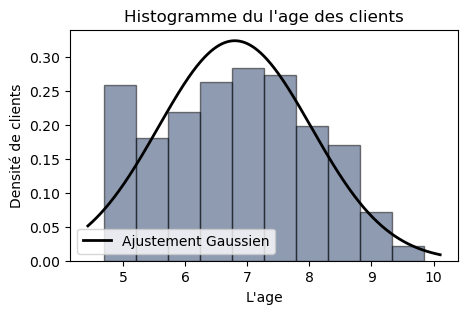

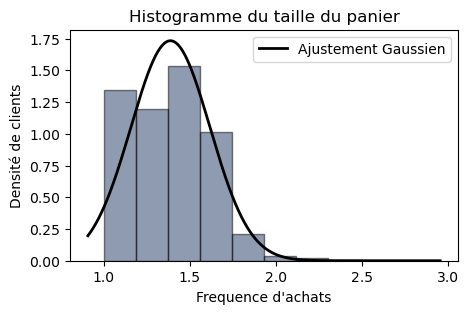

In [58]:
# Visualiser le distribution des variables
# Extraire la colonne 'l'age'
age = np.sqrt(df_group_clients_panier["age"])

# Extraire la colonne 'montant total'
panier = np.sqrt(df_group_clients_panier["panier_moyen"])

# Calculer la moyenne et l'écart type
mean_age = age.mean()
std_age = age.std()

mean_panier = panier.mean()
std_panier = panier.std()

# Afficher les valeurs calculées
print(f"Moyenne du l'age : {mean_age:,.2f}")
print(f"Écart type du l'age : {std_age:,.2f}")

print(f"Moyenne du taille du panier : {mean_freq:,.2f}")
print(f"Écart type du taille du panier : {std_freq:,.2f}")
print()

print("Les deux ensembles de données présentent une asymétrie négative et ne semblent pas respecter les lois de la normalité")
print()


# Tracer l'histogramme avec une courbe gaussienne

### L'age ###
# Histogramme - L'age
plt.figure(figsize=(5, 3))
plt.hist(age, bins=10, density=True, color='#203864', edgecolor='black', alpha=0.5)

# Ajustement gaussien
mu, std = norm.fit(age)
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, age.count())
p = norm.pdf(x, mu, std)

# Tracer la courbe gaussienne
plt.plot(x, p, 'k', linewidth=2, label='Ajustement Gaussien')

# Ajouter les titres et légendes en français
plt.title("Histogramme du l'age des clients")
plt.xlabel("L'age")
plt.ylabel("Densité de clients")
plt.legend()
plt.show()

### Montant ###
# Histogramme - Montant
plt.figure(figsize=(5, 3))
plt.hist(panier, bins=10, density=True, color='#203864', edgecolor='black', alpha=0.5)

# Ajustement gaussien
mu, std = norm.fit(panier)
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, panier.count())
p = norm.pdf(x, mu, std)

# Tracer la courbe gaussienne
plt.plot(x, p, 'k', linewidth=2, label='Ajustement Gaussien')

# Ajouter les titres et légendes en français
plt.title("Histogramme du taille du panier")
plt.xlabel("Frequence d'achats")
plt.ylabel("Densité de clients")
plt.legend()

# Afficher le graphique
plt.savefig("Hist_norm_taille_panier.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.
plt.show()


In [59]:
# Test Shapiro pour tester la normalite

### L'age ###
# Effectuer le test de Shapiro-Wilk
print("Shapiro test pour le variable l'age")
stat, p_value = shapiro(age)

# Afficher les résultats
print(f"Statistique du test de Shapiro-Wilk : {stat:,.2f}")
print(f"Valeur p : {p_value:,.4f}")

# Interprétation des résultats
alpha = 0.05
if p_value > alpha:
    print("Les données suivent une distribution normale (on ne rejette pas H0)")
else:
    print("Les données ne suivent pas une distribution normale (on rejette H0)")
print()

### Taille du panier ###
# Effectuer le test de Shapiro-Wilk
print("Shapiro test pour le variable taille du panier")
stat, p_value = shapiro(panier)

# Afficher les résultats
print(f"Statistique du test de Shapiro-Wilk : {stat:,.2f}")
print(f"Valeur p : {p_value:,.4f}")

# Interprétation des résultats
alpha = 0.05
if p_value > alpha:
    print("Les données suivent une distribution normale (on ne rejette pas H0)")
else:
    print("Les données ne suivent pas une distribution normale (on rejette H0)")
print()

print("Les tests de Shapiro confirme les histogrammes")


Shapiro test pour le variable l'age
Statistique du test de Shapiro-Wilk : 0.98
Valeur p : 0.0000
Les données ne suivent pas une distribution normale (on rejette H0)

Shapiro test pour le variable taille du panier
Statistique du test de Shapiro-Wilk : 0.97
Valeur p : 0.0000
Les données ne suivent pas une distribution normale (on rejette H0)

Les tests de Shapiro confirme les histogrammes


C:\Users\matil\anaconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:531: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 8596.
  res = hypotest_fun_out(*samples, **kwds)


In [60]:
# Test Shapiro pour tester la normalite sur données transforme

### L'age ###
# Effectuer le test de Shapiro-Wilk
print("Shapiro test pour le variable l'age racine carre transformé")
stat, p_value = shapiro(np.sqrt(age))

# Afficher les résultats
print(f"Statistique du test de Shapiro-Wilk : {stat:,.2f}")
print(f"Valeur p : {p_value}")

# Interprétation des résultats
alpha = 0.05
if p_value > alpha:
    print("Les données suivent une distribution normale (on ne rejette pas H0)")
else:
    print("Les données ne suivent pas une distribution normale (on rejette H0)")
print()

### Taille du panier ###
# Effectuer le test de Shapiro-Wilk
print("Shapiro test pour le variable taille du panier racine carre transformé")
stat, p_value = shapiro(np.sqrt(panier))

# Afficher les résultats
print(f"Statistique du test de Shapiro-Wilk : {stat:,.2f}")
print(f"Valeur p : {p_value}")

# Interprétation des résultats
alpha = 0.05
if p_value > alpha:
    print("Les données suivent une distribution normale (on ne rejette pas H0)")
else:
    print("Les données ne suivent pas une distribution normale (on rejette H0)")
print()

print("Les tests de Shapiro confirme les histogrammes")


Shapiro test pour le variable l'age racine carre transformé
Statistique du test de Shapiro-Wilk : 0.98
Valeur p : 6.295209604649607e-36
Les données ne suivent pas une distribution normale (on rejette H0)

Shapiro test pour le variable taille du panier racine carre transformé
Statistique du test de Shapiro-Wilk : 0.98
Valeur p : 8.834237941662062e-36
Les données ne suivent pas une distribution normale (on rejette H0)

Les tests de Shapiro confirme les histogrammes


In [62]:
# Comme les variables ne suivent pas une distribution normale, on dois faire une:
# test Spearmans correlation, non parametric



Coefficient de corrélation de Spearman: -0.206
Valeur p: 2.2169294100814704e-83

Conclusions: Les deux tests indiquent une faible corrélation négative, hautement significative. 
Il convient d'être prudent compte tenu de la taille très importante de l'échantillon, qui peut rendre significatives de faibles corrélations.



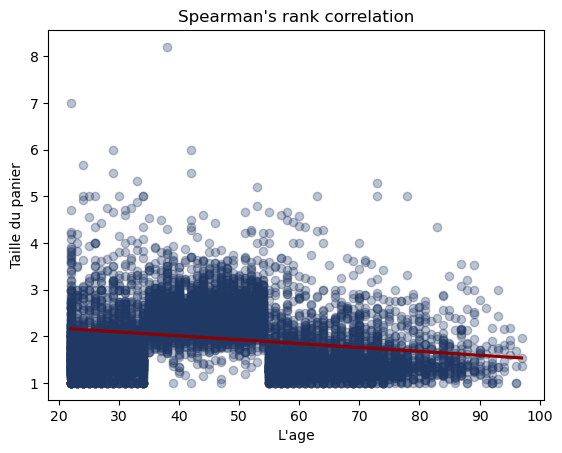

In [63]:
# test Spearmans correlation, non parametric
# Extraire les colonnes pertinentes
age = (df_group_clients_panier["age"])
panier = (df_group_clients_panier["panier_moyen"])

# Visualisation de la tendance
sns.regplot(x=age, y=panier, robust=True, scatter_kws = {"color": "#203864", "alpha": 0.3}, line_kws=dict(color="darkred"))
plt.title("Spearman's rank correlation")
plt.xlabel("L'age")
plt.ylabel("Taille du panier")
plt.savefig("fig_Spearmans_corr_age_taille_panier.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.

print()

# Calculer le coefficient de corrélation de Spearman et la valeur p
spearman_corr, spearman_p_value = spearmanr(age, panier)

print(f"Coefficient de corrélation de Spearman: {spearman_corr:,.3f}")
print(f"Valeur p: {spearman_p_value}")
print()

print("Conclusions: Les deux tests indiquent une faible corrélation négative, hautement significative. \nIl convient d'être prudent compte tenu de la taille très importante de l'échantillon, qui peut rendre significatives de faibles corrélations.")
print()

<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">Etape 2.5 - Corrélation: age versus taille du panier moyen</h3>
</div>

In [64]:
# correlation entres une variable quantitative et une variable qualitative (l'age et catégorie des livres) => ANOVA
print("La corrélation entre deux variables quantitative (l'age et catégorie des livres) => test ANOVA")
print()
#print()
print("H0:   Les moyennes d'age entres les trois catégories de livres sont la même")
print()
print("H1:   Au moins un des moyens de l'age entres les catégories est différent, \n      c'est-à-dire que les clients qui achètent les différentes catégories de livres sont d'âges différents")


La corrélation entre deux variables quantitative (l'age et catégorie des livres) => test ANOVA

H0:   Les moyennes d'age entres les trois catégories de livres sont la même

H1:   Au moins un des moyens de l'age entres les catégories est différent, 
      c'est-à-dire que les clients qui achètent les différentes catégories de livres sont d'âges différents


In [65]:
# les données - le dataset complet
df_all_sans_BtoB.head(3)

,Unnamed: 0,id_prod,date,session_id,client_id,sex,birth,age,price,categ,date_y_m_d,date_y_m,age_decade
0,480353,0_1259,2021-03-01 00:01:07.843138,s_1,c_329,f,1967,59,11.99,0,2021-03-01,2021-03,50
1,428221,0_1390,2021-03-01 00:02:26.047414,s_2,c_664,m,1960,66,19.37,0,2021-03-01,2021-03,60
2,462423,0_1352,2021-03-01 00:02:38.311413,s_3,c_580,m,1988,38,4.50,0,2021-03-01,2021-03,30


C:\Users\matil\AppData\Local\Temp\ipykernel_25800\211428738.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x = "categ", y = "age", data = df_all_sans_BtoB, palette=["#d5a419","#006390","#008fa4"]);


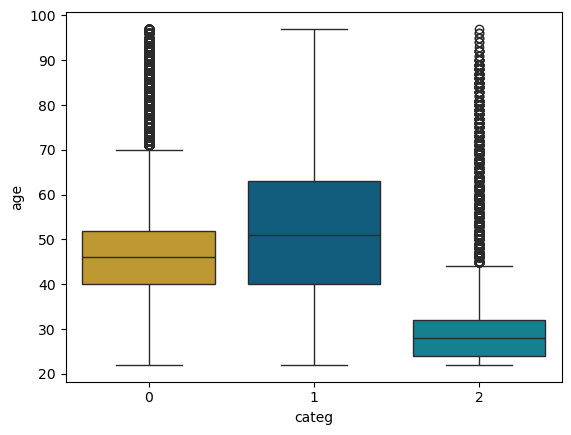

In [66]:
# visualiser les données pour regarde le normalite entres groupes
sns.boxplot(x = "categ", y = "age", data = df_all_sans_BtoB, palette=["#d5a419","#006390","#008fa4"]);
plt.show()



C:\Users\matil\AppData\Local\Temp\ipykernel_25800\122807279.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x = (df_all_sans_BtoB["categ"]), y = np.log(df_all_sans_BtoB["age"]),palette=["#d5a419","#006390","#008fa4"]);


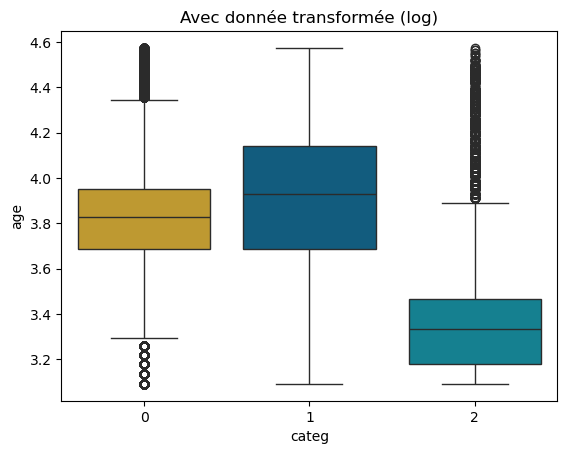

In [67]:
# visualiser les données pour regarde le normalite entres groupes avec le données log transformer
df_all_sans_BtoB["log_age"] = np.log(df_all_sans_BtoB["age"])
df_all_sans_BtoB.head()

sns.boxplot(x = (df_all_sans_BtoB["categ"]), y = np.log(df_all_sans_BtoB["age"]),palette=["#d5a419","#006390","#008fa4"]);
plt.title("Avec donnée transformée (log)")
plt.show()

In [ ]:
#### Test ANOVA
# On visualise nos variables d'intérêts
sns.boxplot(x="categ", y="age", data=df_all_sans_BtoB, palette=["#d5a419","#006390","#008fa4"])

# Sélectionner les colonnes pertinentes pour chaque type de voyage
#aventure = data_ANOVA[data_ANOVA['type de voyage'] == 'aventure']['évaluation sur 5'].dropna()
#detente = data_ANOVA[data_ANOVA['type de voyage'] == 'détente']['évaluation sur 5'].dropna()
#culturel = data_ANOVA[data_ANOVA['type de voyage'] == 'culturel']['évaluation sur 5'].dropna()
categ0 = df_all_sans_BtoB[df_all_sans_BtoB["categ"] == 0]["age"]
categ1 = df_all_sans_BtoB[df_all_sans_BtoB["categ"] == 1]["age"]
categ2 = df_all_sans_BtoB[df_all_sans_BtoB["categ"] == 2]["age"]

# Calculer le test ANOVA et la valeur p
f_stat, p_value = f_oneway(categ0, categ1, categ2)

print(f"Statistique de test F: {f_stat}")
print(f"Valeur p: {p_value}")


C:\Users\matil\AppData\Local\Temp\ipykernel_25800\1513158448.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="categ", y="age", data=df_all_sans_BtoB, palette=["#d5a419","#006390","#008fa4"])


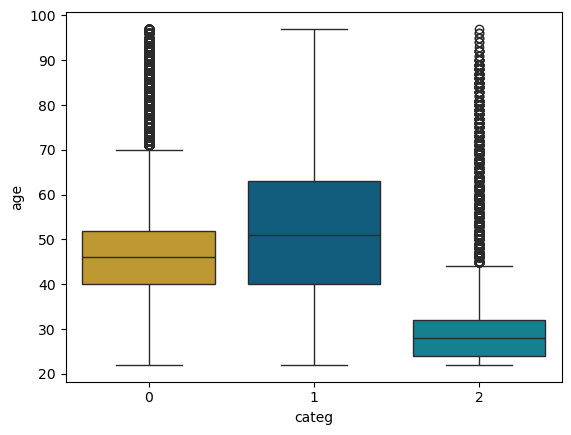

C:\Users\matil\AppData\Local\Temp\ipykernel_25800\1513158448.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="categ", y="log_age", data=df_all_sans_BtoB, palette=["#d5a419","#006390","#008fa4"])


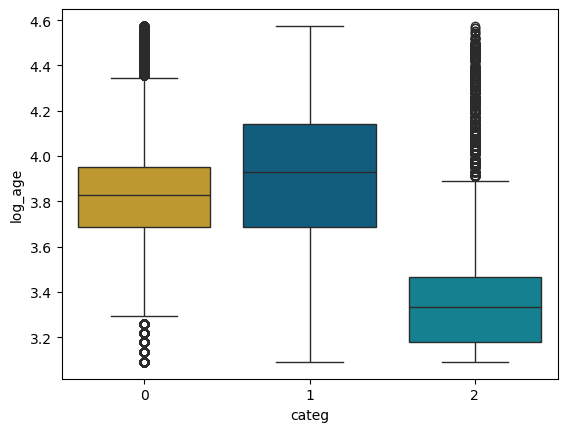

ANOVA statistique de test F: 56248.81920260949
ANOVA valeur p: 0.0

Kruskal-Wallis statistique de test Chi-2: 72209.48289794501
Kruskal-Wallis valeur p: 0.0

Les données brutes et transformées présentent toutes deux un nombre élevé de valeurs aberrantes. 
Le test de Kruskal-Wallis est donc plus fiable.


In [74]:
# Les données brutes et transformées présentent toutes deux un nombre élevé de valeurs aberrantes et une distribution légèrement non normale.
# Le test de Kruskal-Wallis est donc plus fiable.

#### Test ANOVA

# On visualise nos variables d'intérêts
sns.boxplot(x="categ", y="age", data=df_all_sans_BtoB, palette=["#d5a419","#006390","#008fa4"])
plt.savefig("fig_Kruskal_Wallis_age_categ.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.
plt.show()
sns.boxplot(x="categ", y="log_age", data=df_all_sans_BtoB, palette=["#d5a419","#006390","#008fa4"])
plt.show()
# Sélectionner les colonnes pertinentes pour chaque type de voyage
#aventure = data_ANOVA[data_ANOVA['type de voyage'] == 'aventure']['évaluation sur 5'].dropna()
#detente = data_ANOVA[data_ANOVA['type de voyage'] == 'détente']['évaluation sur 5'].dropna()
#culturel = data_ANOVA[data_ANOVA['type de voyage'] == 'culturel']['évaluation sur 5'].dropna()
categ0 = df_all_sans_BtoB[df_all_sans_BtoB["categ"] == 0]["log_age"]
categ1 = df_all_sans_BtoB[df_all_sans_BtoB["categ"] == 1]["log_age"]
categ2 = df_all_sans_BtoB[df_all_sans_BtoB["categ"] == 2]["log_age"]

# Calculer le test ANOVA et la valeur p
f_stat, p_value = f_oneway(categ0, categ1, categ2)

print(f"ANOVA statistique de test F: {f_stat}")
print(f"ANOVA valeur p: {p_value}")
print()

### Conduct the Kruskal-Wallis Test 
chi_stat, p_value = stats.kruskal(categ0, categ1, categ2)

# Print the result
print(f"Kruskal-Wallis statistique de test Chi-2: {chi_stat}")
print(f"Kruskal-Wallis valeur p: {p_value}")

print()
print("Les données brutes et transformées présentent toutes deux un nombre élevé de valeurs aberrantes. \nLe test de Kruskal-Wallis est donc plus fiable.")

In [76]:
# Test post hoc pour identifier où se situe la différence statistique
# Perform Tukey's HSD test
tukey = pairwise_tukeyhsd(endog=df_all_sans_BtoB["log_age"], groups=df_all_sans_BtoB["categ"], alpha=0.05)
print(tukey)

Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj  lower   upper  reject
---------------------------------------------------
     0      1   0.0574   0.0  0.0557  0.0591   True
     0      2  -0.4775   0.0 -0.4812 -0.4739   True
     1      2  -0.5349   0.0 -0.5387 -0.5312   True
---------------------------------------------------
